# Mini DDPM — Fashion-MNIST 32×32 (PyTorch murni)
Model difusi skala kecil yang belajar memprediksi noise pada gambar kecil, tanpa library `diffusers`.
Tantangan utama: **noise schedule** (linear vs cosine) dan **timestep embedding** (dengan vs tanpa).

**Isi notebook (satu file, jalankan dari atas ke bawah):**
1. Data pipeline · 2. Model (timestep embedding + U-Net) · 3. Difusi & noise schedule · 4. Training · 5. Tuning hyperparameter · 6. Evaluasi & perbandingan · 7. Tes

> Training default **dimatikan** (`RUN_TRAINING = False`) karena ±42 menit per run di RTX 3060 Ti. Hasil 3 run yang sudah dilatih
> (`linear`, `cosine`, `linear_notime`) dibaca dari `checkpoints/` dan `reports/`.

In [88]:
# Semua import di satu tempat
import copy
import json
import math
import os
import time
from IPython.display import Image, display, Markdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from torch.utils.data import Dataset, DataLoader, Subset
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import torchvision.utils as vutils
from tqdm import tqdm
import yaml

In [89]:
# Notebook dijalankan dari folder notebooks/, sedangkan path data/, checkpoints/, reports/
# relatif ke root repo -> pindah ke root.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Folder kerja:", os.getcwd())

Folder kerja: e:\Kuliah\GenAI\TUBES MIDTERM\GenerativeAI


# 1. Data pipeline
Kontrak: tensor `[B,1,32,32]` di `[-1,1]`, tanpa label. Split stratified 55.000 / 5.000 / 10.000, padding 2 piksel hitam (→ `-1`).

In [90]:
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

In [91]:
class DataConfig:
    def __init__(self, config_dict):
        self.seed = config_dict.get('seed', 42)
        data = config_dict.get('data', {})
        self.root = data.get('root', 'data')
        self.val_size = data.get('val_size', 5000)
        self.batch_size = data.get('batch_size', 128)
        self.num_workers = data.get('num_workers', 0)
        self.pin_memory = data.get('pin_memory', False)
        self.download = data.get('download', True)
        self.horizontal_flip_p = data.get('horizontal_flip_p', 0.5)
        self.drop_last_train = data.get('drop_last_train', False)

In [92]:
def load_data_config(path='configs/default.yaml'):
    with open(path, 'r') as f:
        return DataConfig(yaml.safe_load(f))

In [93]:
def seed_data(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [94]:
class FashionDataset(Dataset):
    """
    Dataset wrapper untuk mengembalikan TENSOR SAJA [1, 32, 32] di rentang [-1, 1].
    Sesuai kontrak DDPM (tanpa kondisi teks/label).
    """
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform
        
        # Ekstrak target untuk kebutuhan stratifikasi dan inspeksi
        if hasattr(subset, 'dataset') and hasattr(subset, 'indices'):
            self.targets = torch.tensor([subset.dataset.targets[i] for i in subset.indices])
        else:
            self.targets = subset.targets.clone().detach() if isinstance(subset.targets, torch.Tensor) else torch.tensor(subset.targets)

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, _ = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img  # Return ONLY image tensor

In [95]:
def get_transforms(is_train: bool, config: DataConfig) -> transforms.Compose:
    t_list = []
    if is_train and config.horizontal_flip_p > 0:
        t_list.append(transforms.RandomHorizontalFlip(p=config.horizontal_flip_p))
    
    t_list.extend([
        transforms.ToTensor(), # [0, 1]
        transforms.Pad(2, fill=0), # Pad hitam (0) -> 32x32
        transforms.Normalize([0.5], [0.5]) # [0, 1] -> [-1, 1]. Hitam jadi -1
    ])
    return transforms.Compose(t_list)

In [96]:
def build_datasets(config: DataConfig):
    seed_data(config.seed)
    
    # Download raw dataset
    base_train_val = datasets.FashionMNIST(root=config.root, train=True, download=config.download)
    test_raw = datasets.FashionMNIST(root=config.root, train=False, download=config.download)
    
    # Stratified Split 55k Train, 5k Val
    targets = base_train_val.targets.numpy()
    classes = np.unique(targets)
    val_per_class = config.val_size // len(classes)
    
    train_idx, val_idx = [], []
    for c in classes:
        c_idx = np.where(targets == c)[0]
        np.random.shuffle(c_idx)
        val_idx.extend(c_idx[:val_per_class])
        train_idx.extend(c_idx[val_per_class:])
        
    train_subset = Subset(base_train_val, train_idx)
    val_subset = Subset(base_train_val, val_idx)
    
    # Apply transforms
    train_ds = FashionDataset(train_subset, get_transforms(True, config))
    val_ds = FashionDataset(val_subset, get_transforms(False, config))
    test_ds = FashionDataset(test_raw, get_transforms(False, config))
    
    return train_ds, val_ds, test_ds

In [97]:
class DataLoaderWrapper:
    def __init__(self, train, val, test):
        self.train = train
        self.val = val
        self.test = test

In [98]:
def build_dataloaders(config: DataConfig):
    train_ds, val_ds, test_ds = build_datasets(config)
    
    # Generator independen untuk validasi agar tidak mengganggu RNG training
    g_val = torch.Generator()
    g_val.manual_seed(config.seed)
    
    train_dl = DataLoader(train_ds, batch_size=config.batch_size, shuffle=True, 
                          num_workers=config.num_workers, pin_memory=config.pin_memory, 
                          drop_last=config.drop_last_train)
                          
    val_dl = DataLoader(val_ds, batch_size=config.batch_size, shuffle=False, 
                        num_workers=config.num_workers, pin_memory=config.pin_memory,
                        drop_last=False, generator=g_val)
                        
    test_dl = DataLoader(test_ds, batch_size=config.batch_size, shuffle=False, 
                         num_workers=config.num_workers, pin_memory=config.pin_memory,
                         drop_last=False)
                         
    return DataLoaderWrapper(train_dl, val_dl, test_dl)

In [99]:
def to_display(images: torch.Tensor, crop=True):
    """
    Mengembalikan tensor gambar ke rentang [0, 1] dan menghapus padding.
    """
    imgs = (images * 0.5) + 0.5
    imgs = torch.clamp(imgs, 0, 1)
    if crop:
        imgs = imgs[..., 2:-2, 2:-2] # 32x32 -> 28x28
    return imgs

In [100]:
def audit_loader(loader, name):
    print(f"Memproses {name} loader...")
    total_images = 0
    min_val = float('inf')
    max_val = float('-inf')
    has_nan_or_inf = False
    last_batch_size = 0
    
    for batch in loader:
        b_size = batch.size(0)
        total_images += b_size
        last_batch_size = b_size
        
        if not torch.isfinite(batch).all():
            has_nan_or_inf = True
            
        min_val = min(min_val, batch.min().item())
        max_val = max(max_val, batch.max().item())
        
    return {
        "total_images": total_images,
        "total_batches": len(loader),
        "last_batch_size": last_batch_size,
        "min_val": round(min_val, 4),
        "max_val": round(max_val, 4),
        "has_nan_or_inf": has_nan_or_inf
    }

In [101]:
def save_preview(loader, name):
    # Ambil satu batch untuk divisualisasikan
    batch = next(iter(loader))
    images = batch[:16] # Ambil 16 gambar pertama saja
    
    # Gunakan fungsi to_display untuk hapus padding (jadi 28x28) dan kembalikan ke rentang [0, 1]
    disp_images = to_display(images, crop=True)
    
    grid = make_grid(disp_images, nrow=4, padding=2, normalize=False)
    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0).numpy(), cmap='gray')
    plt.axis('off')
    plt.title(f"Preview {name.capitalize()} (28x28, Rentang [0,1])")
    plt.tight_layout()
    
    path = f"reports/data/{name}_preview.png"
    plt.savefig(path)
    plt.close()

In [102]:
def run_full_inspection():
    os.makedirs("reports/data", exist_ok=True)
    config = load_data_config()
    loaders = build_dataloaders(config)
    
    print("=== AUDIT KESELURUHAN DATASET NYATA ===")
    results = {}
    
    for name, loader in [("train", loaders.train), ("val", loaders.val), ("test", loaders.test)]:
        results[name] = audit_loader(loader, name)
        save_preview(loader, name)
        
    with open("reports/data/summary.json", "w") as f:
        json.dump(results, f, indent=4)
        
    print("\n=== RINGKASAN HASIL ===")
    print(json.dumps(results, indent=2))
    
    print("\n=== PEMERIKSAAN BATCH TERAKHIR ===")
    print(f"Target  -> Train: 88, Val: 8, Test: 16")
    print(f"Aktual  -> Train: {results['train']['last_batch_size']}, Val: {results['val']['last_batch_size']}, Test: {results['test']['last_batch_size']}")
    print("Gambar preview telah disimpan di folder reports/data/")

In [103]:
config = load_data_config("configs/default.yaml")
print(vars(config))
loaders = build_dataloaders(config)

{'seed': 42, 'root': 'data', 'val_size': 5000, 'batch_size': 128, 'num_workers': 0, 'pin_memory': False, 'download': True, 'horizontal_flip_p': 0.5, 'drop_last_train': False}


In [104]:
audit = {name: audit_loader(loader, name)
         for name, loader in [("train", loaders.train), ("val", loaders.val), ("test", loaders.test)]}
pd.DataFrame(audit).T

Memproses train loader...
Memproses val loader...
Memproses test loader...


,total_images,total_batches,last_batch_size,min_val,max_val,has_nan_or_inf
train,55000,430,88,-1.0,1.0,False
val,5000,40,8,-1.0,1.0,False
test,10000,79,16,-1.0,1.0,False


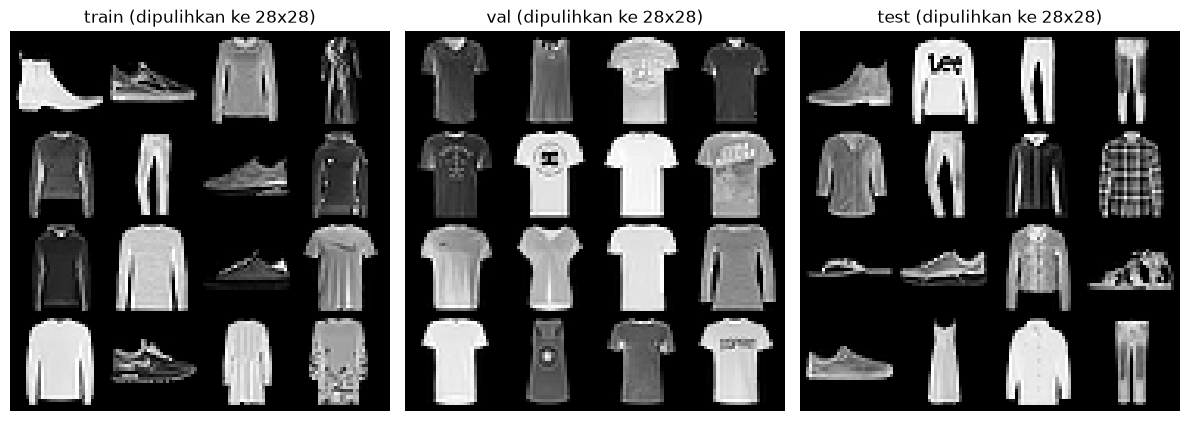

In [105]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4.3))
for a, (name, loader) in zip(ax, [("train", loaders.train), ("val", loaders.val), ("test", loaders.test)]):
    grid = make_grid(to_display(next(iter(loader))[:16]), nrow=4, padding=2)
    a.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray"); a.axis("off"); a.set_title(f"{name} (dipulihkan ke 28x28)")
plt.tight_layout(); plt.show()

In [106]:
_, val_ds, _ = build_datasets(config)
counts = torch.bincount(val_ds.targets)
pd.Series(counts.numpy(), index=CLASS_NAMES, name="jumlah")

T-shirt/top    500
Trouser        500
Pullover       500
Dress          500
Coat           500
Sandal         500
Shirt          500
Sneaker        500
Bag            500
Ankle boot     500
Name: jumlah, dtype: int64

# 2. Model


## 1. Timestep embedding
Model harus tahu **langkah noise `t`** yang sedang diproses. `t` dipetakan ke vektor sinus/kosinus dengan frekuensi
geometris (seperti positional encoding Transformer):

$$\mathrm{emb}(t)_{2i}=\sin(t\,\omega_i),\quad \mathrm{emb}(t)_{2i+1}=\cos(t\,\omega_i),\quad \omega_i=10000^{-i/(d/2-1)}$$

Vektor ini diproyeksikan MLP di `UNet`, lalu disuntikkan ke setiap `ResBlock` (ditambahkan ke fitur sebelum conv kedua).


In [107]:
class SinusoidalTimeEmbedding(nn.Module):
    """Memetakan timestep t ke vektor sinus/kosinus (tanpa MLP; proyeksi ada di UNet)."""
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
        half_dim = dim // 2

        emb = math.log(10000) / (half_dim - 1)
        freqs = torch.exp(torch.arange(half_dim, dtype=torch.float32) * -emb)
        self.register_buffer("freqs", freqs, persistent=False)

    def forward(self, t):
        """
        Args:
            t (torch.LongTensor): Timestep, shape (B,)
        Returns:
            torch.Tensor: Embedding sinusoidal, shape (B, dim)
        """
        args = t.float().unsqueeze(1) * self.freqs.unsqueeze(0)
        embeddings = torch.cat([args.sin(), args.cos()], dim=-1)

        if self.dim % 2 == 1:
            embeddings = F.pad(embeddings, (0, 1, 0, 0))

        return embeddings

### Blok pembangun: ResBlock, Attention, Down/Upsample

In [108]:
class ResBlock(nn.Module):
    """
    Residual block pre-activation. Jika time_emb_dim=None, injeksi waktu dilewati
    (dipakai untuk ablasi tanpa time embedding).
    """
    def __init__(self, in_channels, out_channels, time_emb_dim=None, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(num_groups=groups, num_channels=in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)

        if time_emb_dim is not None:
            self.time_mlp = nn.Sequential(
                nn.SiLU(),
                nn.Linear(time_emb_dim, out_channels)
            )
        else:
            self.time_mlp = None

        self.norm2 = nn.GroupNorm(num_groups=groups, num_channels=out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)

        if in_channels != out_channels:
            self.shortcut = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        else:
            self.shortcut = nn.Identity()

    def forward(self, x, t_emb=None):
        h = self.norm1(x)
        h = F.silu(h)
        h = self.conv1(h)

        if self.time_mlp is not None:
            h = h + self.time_mlp(t_emb).view(-1, h.shape[1], 1, 1)

        h = self.norm2(h)
        h = F.silu(h)
        h = self.conv2(h)

        return h + self.shortcut(x)

In [109]:
class AttentionBlock(nn.Module):
    """Multi-Head Self-Attention dengan pre-GroupNorm dan koneksi residual."""
    def __init__(self, channels, num_heads=4, groups=8):
        super().__init__()
        assert channels % num_heads == 0, "Channels harus habis dibagi num_heads"
        self.norm = nn.GroupNorm(num_groups=groups, num_channels=channels)
        self.mha = nn.MultiheadAttention(embed_dim=channels, num_heads=num_heads, batch_first=True)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x)

        h = h.reshape(B, C, H * W).transpose(1, 2)
        attn_out, _ = self.mha(h, h, h)
        attn_out = attn_out.transpose(1, 2).reshape(B, C, H, W)

        return x + attn_out

In [110]:
class Downsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)

In [111]:
class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=2.0, mode='nearest')
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, padding=1)

    def forward(self, x):
        return self.conv(self.upsample(x))


## 2. U-Net
Memprediksi noise ε dari $(x_t, t)$. Dua level resolusi (32→16→8), 1 blok self-attention di bottleneck.
`use_time_emb=False` mematikan seluruh jalur `t` (dipakai untuk ablasi).


In [112]:
class UNet(nn.Module):
    """
    U-Net prediksi noise untuk input (B, in_channels, H, W) dan timestep (B,).
    H dan W harus habis dibagi 4 (dua kali downsample), mis. 32x32.

    use_time_emb=False menonaktifkan seluruh jalur timestep (untuk ablasi):
    model tidak tahu t sama sekali.
    """
    def __init__(self, in_channels=1, base_channels=64, time_emb_dim=256, use_time_emb=True):
        super().__init__()
        self.use_time_emb = use_time_emb
        c = base_channels

        if use_time_emb:
            self.time_emb = SinusoidalTimeEmbedding(dim=64)
            self.time_mlp = nn.Sequential(
                nn.Linear(64, time_emb_dim),
                nn.SiLU(),
                nn.Linear(time_emb_dim, time_emb_dim)
            )
            ted = time_emb_dim
        else:
            ted = None

        self.init_conv = nn.Conv2d(in_channels, c, kernel_size=3, padding=1)

        self.enc_res1 = ResBlock(c, c, ted)
        self.enc_res2 = ResBlock(c, c, ted)
        self.down1 = Downsample(c)

        self.enc_res3 = ResBlock(c, c * 2, ted)
        self.enc_res4 = ResBlock(c * 2, c * 2, ted)
        self.down2 = Downsample(c * 2)

        self.bot_res1 = ResBlock(c * 2, c * 2, ted)
        self.bot_attn = AttentionBlock(c * 2, num_heads=4, groups=8)
        self.bot_res2 = ResBlock(c * 2, c * 2, ted)

        self.up1 = Upsample(c * 2)
        self.dec_res1 = ResBlock(c * 2 + c * 2, c * 2, ted)
        self.dec_res2 = ResBlock(c * 2 + c * 2, c * 2, ted)

        self.up2 = Upsample(c * 2)
        self.dec_res3 = ResBlock(c * 2 + c, c, ted)
        self.dec_res4 = ResBlock(c + c, c, ted)

        self.out_norm = nn.GroupNorm(num_groups=8, num_channels=c)
        self.out_conv = nn.Conv2d(c, in_channels, kernel_size=3, padding=1)

    def forward(self, x, t):
        t_emb = self.time_mlp(self.time_emb(t)) if self.use_time_emb else None
        skips = []

        x = self.init_conv(x)

        x = self.enc_res1(x, t_emb); skips.append(x)
        x = self.enc_res2(x, t_emb); skips.append(x)
        x = self.down1(x)

        x = self.enc_res3(x, t_emb); skips.append(x)
        x = self.enc_res4(x, t_emb); skips.append(x)
        x = self.down2(x)

        x = self.bot_res1(x, t_emb)
        x = self.bot_attn(x)
        x = self.bot_res2(x, t_emb)

        x = self.up1(x)
        x = torch.cat([x, skips.pop()], dim=1)
        x = self.dec_res1(x, t_emb)

        x = torch.cat([x, skips.pop()], dim=1)
        x = self.dec_res2(x, t_emb)

        x = self.up2(x)
        x = torch.cat([x, skips.pop()], dim=1)
        x = self.dec_res3(x, t_emb)

        x = torch.cat([x, skips.pop()], dim=1)
        x = self.dec_res4(x, t_emb)

        x = self.out_norm(x)
        x = F.silu(x)
        return self.out_conv(x)

# 3. Difusi & noise schedule


## 3. Noise schedule & proses difusi
**Forward:** $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$, dengan $\bar\alpha_t=\prod_{s\le t}(1-\beta_s)$.
**Loss:** $\mathbb{E}\,\lVert\epsilon-\epsilon_\theta(x_t,t)\rVert^2$. Dua schedule tersedia: `linear` (Ho et al.) dan `cosine` (Nichol & Dhariwal).
**Sampling:** DDIM (`sample_ddim`), 50 langkah dari 1000.


In [113]:
def get_beta_schedule(schedule_type, num_timesteps, s=0.008):
    if schedule_type == "linear":
        return torch.linspace(1e-4, 0.02, num_timesteps, dtype=torch.float32)
    elif schedule_type == "cosine":
        steps = num_timesteps + 1
        x = torch.linspace(0, num_timesteps, steps, dtype=torch.float32)
        alphas_cumprod = torch.cos(((x / num_timesteps) + s) / (1 + s) * math.pi * 0.5) ** 2
        alphas_cumprod = alphas_cumprod / alphas_cumprod[0]
        betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
        return torch.clip(betas, 0, 0.999)

In [114]:
class GaussianDiffusion(nn.Module):
    def __init__(self, num_timesteps=1000, schedule="linear"):
        super().__init__()
        self.num_timesteps = num_timesteps
        
        betas = get_beta_schedule(schedule, num_timesteps)
        alphas = 1.0 - betas
        alphas_cumprod = torch.cumprod(alphas, dim=0)
        alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)
        
        self.register_buffer("betas", betas)
        self.register_buffer("alphas_cumprod", alphas_cumprod)
        self.register_buffer("sqrt_alphas_cumprod", torch.sqrt(alphas_cumprod))
        self.register_buffer("sqrt_one_minus_alphas_cumprod", torch.sqrt(1.0 - alphas_cumprod))
        
        # Varian variance: beta_t atau posterior variance (beta_tilde)
        posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)
        self.register_buffer("posterior_variance", posterior_variance)

    def extract(self, a, t, x_shape):
        batch_size = t.shape[0]
        out = a.gather(-1, t.long())
        return out.reshape(batch_size, *((1,) * (len(x_shape) - 1)))

    def q_sample(self, x0, t, noise=None):
        if noise is None: noise = torch.randn_like(x0)
        sqrt_a = self.extract(self.sqrt_alphas_cumprod, t, x0.shape)
        sqrt_one_minus_a = self.extract(self.sqrt_one_minus_alphas_cumprod, t, x0.shape)
        return sqrt_a * x0 + sqrt_one_minus_a * noise

    def p_losses(self, model, x0, t, noise=None):
        if noise is None: noise = torch.randn_like(x0)
        x_t = self.q_sample(x0, t, noise=noise)
        pred_noise = model(x_t, t)
        return F.mse_loss(pred_noise, noise)

    @torch.no_grad()
    def sample_ddim(self, model, n=16, channels=1, image_size=32, ddim_timesteps=50, eta=0.0, use_beta_tilde=False, device="cuda", return_intermediates=False):
        model.eval()
        step_size = self.num_timesteps // ddim_timesteps
        time_steps = list(reversed(range(0, self.num_timesteps, step_size)))
        
        x = torch.randn((n, channels, image_size, image_size), device=device)
        intermediates = [x.cpu()] if return_intermediates else None
        
        for i, t_val in enumerate(time_steps):
            t = torch.full((n,), t_val, device=device, dtype=torch.long)
            # Fix DDIM: t_prev harus benar-benar turun ke -1 (logis 0 dengan alpha=1) pada step terakhir
            t_prev_val = time_steps[i + 1] if i < len(time_steps) - 1 else -1
            
            alpha_bar_t = self.extract(self.alphas_cumprod, t, x.shape)
            if t_prev_val >= 0:
                t_prev = torch.full((n,), t_prev_val, device=device, dtype=torch.long)
                alpha_bar_t_prev = self.extract(self.alphas_cumprod, t_prev, x.shape)
            else:
                alpha_bar_t_prev = torch.ones_like(alpha_bar_t) # t=-1 berarti tidak ada noise
            
            pred_noise = model(x, t)
            pred_x0 = (x - torch.sqrt(1.0 - alpha_bar_t) * pred_noise) / torch.sqrt(alpha_bar_t)
            pred_x0 = torch.clamp(pred_x0, -1.0, 1.0)
            
            # Variance
            if use_beta_tilde:
                sigma_t = eta * torch.sqrt(self.extract(self.posterior_variance, t, x.shape))
            else:
                sigma_t = eta * torch.sqrt((1 - alpha_bar_t_prev) / (1 - alpha_bar_t) * (1 - alpha_bar_t / alpha_bar_t_prev))
            
            dir_xt = torch.sqrt((1.0 - alpha_bar_t_prev - sigma_t**2).clamp(min=0.0)) * pred_noise
            noise = torch.randn_like(x) if t_prev_val >= 0 else 0.0
            x = torch.sqrt(alpha_bar_t_prev) * pred_x0 + dir_xt + sigma_t * noise
            if return_intermediates:
                intermediates.append(x.cpu())
                
        model.train()
        if return_intermediates:
            return x, intermediates
        return x

### Visualisasi: noise schedule

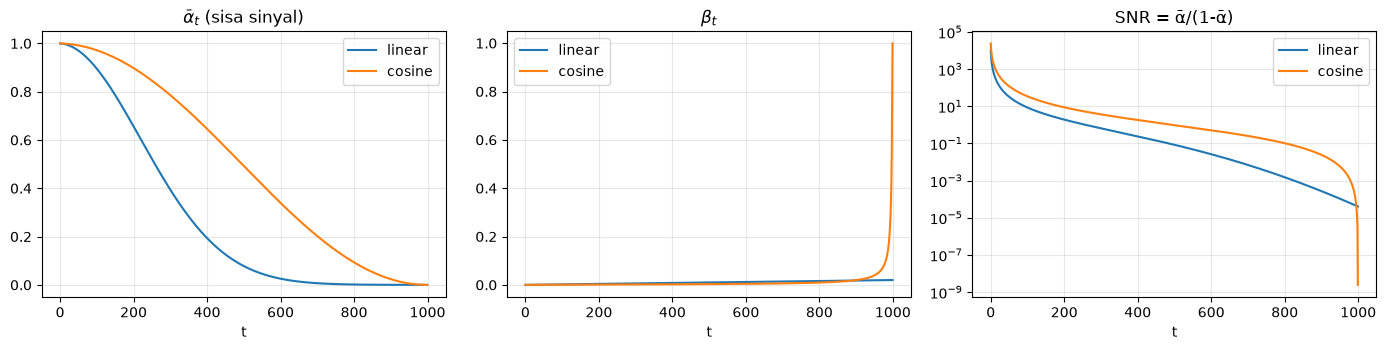

linear  ᾱ_T = 4.04e-05
cosine  ᾱ_T = 2.43e-09


In [115]:
T = 1000
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for name in ("linear", "cosine"):
    d = GaussianDiffusion(num_timesteps=T, schedule=name)
    ab = d.alphas_cumprod
    ax[0].plot(ab, label=name)
    ax[1].plot(d.betas, label=name)
    ax[2].plot(ab / (1 - ab), label=name)
ax[0].set_title(r"$\bar\alpha_t$ (sisa sinyal)"); ax[1].set_title(r"$\beta_t$")
ax[2].set_title("SNR = ᾱ/(1-ᾱ)"); ax[2].set_yscale("log")
for a in ax: a.set_xlabel("t"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()
for name in ("linear", "cosine"):
    print(f"{name:7s} ᾱ_T = {GaussianDiffusion(T, name).alphas_cumprod[-1].item():.2e}")

Linear menghancurkan sinyal lebih cepat di tengah rentang `t`, sedangkan cosine menurunkan ᾱ lebih landai dan
mendekati 0 hanya di ujung. Itu sebabnya angka loss kedua schedule **tidak sebanding** (distribusi tingkat noise per `t` berbeda).

### Visualisasi: timestep embedding

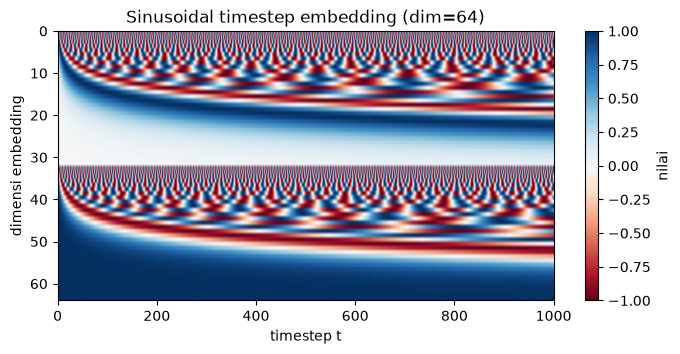

In [116]:
emb = SinusoidalTimeEmbedding(64)(torch.arange(1000))
plt.figure(figsize=(8, 3.5))
plt.imshow(emb.T, aspect="auto", cmap="RdBu", extent=[0, 1000, 64, 0])
plt.xlabel("timestep t"); plt.ylabel("dimensi embedding"); plt.colorbar(label="nilai")
plt.title("Sinusoidal timestep embedding (dim=64)"); plt.show()

Dimensi awal berosilasi cepat (membedakan `t` yang berdekatan), dimensi akhir berosilasi lambat (menandai fase kasar).

### Visualisasi: forward process pada gambar nyata

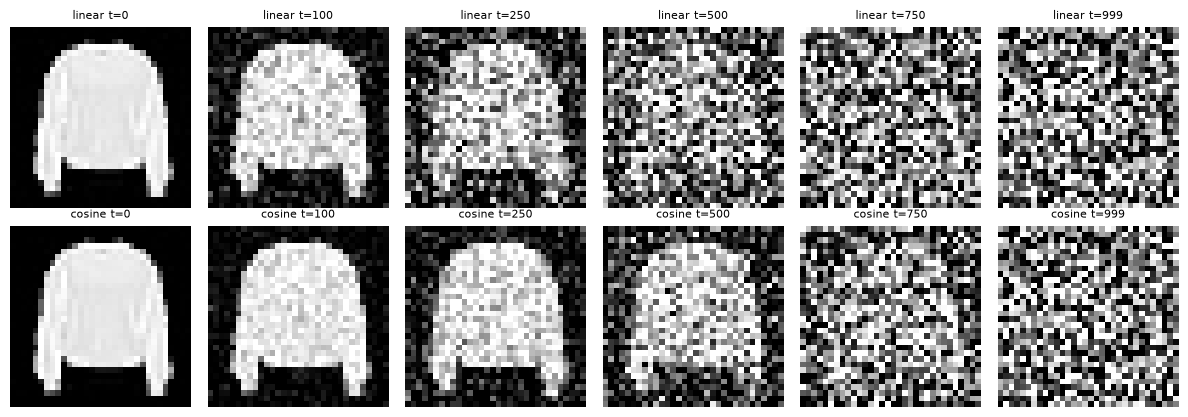

In [117]:
tfm = transforms.Compose([transforms.ToTensor(), transforms.Pad(2), transforms.Normalize([0.5], [0.5])])
x0 = tfm(datasets.FashionMNIST("data", train=True, download=True)[7][0])[None]   # [1,1,32,32] di [-1,1]
ts = [0, 100, 250, 500, 750, 999]
fig, ax = plt.subplots(2, len(ts), figsize=(2 * len(ts), 4.2))
for r, name in enumerate(("linear", "cosine")):
    d = GaussianDiffusion(T, name)
    torch.manual_seed(0)
    for c, t in enumerate(ts):
        xt = d.q_sample(x0, torch.tensor([t]))
        ax[r, c].imshow(((xt[0, 0] + 1) / 2).clamp(0, 1), cmap="gray"); ax[r, c].axis("off")
        ax[r, c].set_title(f"{name} t={t}", fontsize=8)
plt.tight_layout(); plt.show()

### Sanity check model

In [118]:
def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

for flag in (True, False):
    m = UNet(use_time_emb=flag)
    out = m(torch.randn(2, 1, 32, 32), torch.tensor([0, 999]))
    print(f"use_time_emb={flag!s:5}  parameter={count_params(m):,}  output={tuple(out.shape)}")

m = UNet()
x = torch.randn(2, 1, 32, 32)
loss = GaussianDiffusion(T).p_losses(m, x, torch.randint(0, T, (2,)))
loss.backward()
print("loss awal (acak):", round(loss.item(), 4), "| backward OK")

use_time_emb=True   parameter=3,390,721  output=(2, 1, 32, 32)
use_time_emb=False  parameter=3,045,121  output=(2, 1, 32, 32)
loss awal (acak): 1.3254 | backward OK


# 4. Training
Loop dengan AdamW, EMA, AMP, gradient clipping; checkpoint terbaik dipilih dari **val loss** (bobot EMA).

In [119]:
class EMA:
    """Implementasi Exponential Moving Average sederhana untuk parameter model."""
    def __init__(self, model, decay=0.999):
        self.model = model
        self.decay = decay
        self.shadow = {k: v.clone().detach() for k, v in model.named_parameters()}

    def step(self):
        with torch.no_grad():
            for name, param in self.model.named_parameters():
                if param.requires_grad:
                    self.shadow[name].sub_((1.0 - self.decay) * (self.shadow[name] - param))

    def copy_to(self, model):
        for name, param in model.named_parameters():
            if param.requires_grad:
                param.data.copy_(self.shadow[name])

In [120]:
@torch.no_grad()
def validate(model, diffusion, dataloader, device, seed=0):
    """Rata-rata loss pada val set. Timestep dan noise memakai seed tetap agar
    nilainya sebanding antar epoch dan antar run."""
    model.eval()
    g = torch.Generator(device=device)
    g.manual_seed(seed)
    total, count = 0.0, 0
    for batch in dataloader:
        x0 = batch.to(device)
        t = torch.randint(0, diffusion.num_timesteps, (x0.shape[0],), device=device, generator=g)
        noise = torch.randn(x0.shape, device=device, generator=g)
        with torch.amp.autocast('cuda'):
            loss = diffusion.p_losses(model, x0, t, noise=noise)
        total += loss.item() * x0.shape[0]
        count += x0.shape[0]
    return total / count

In [121]:
def train(model, diffusion, dataloader, val_dataloader=None, epochs=50, lr=2e-4,
          device="cuda", out_dir="checkpoints/default"):
    """
    Melatih model dan menulis ke out_dir:
      - best_model.pth    : bobot EMA dengan val loss terendah (train loss jika val_dataloader=None)
      - training_log.csv  : epoch, train_loss, val_loss (ditulis tiap epoch)
    """
    os.makedirs(out_dir, exist_ok=True)
    optimizer = optim.AdamW(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler('cuda')
    ema = EMA(model)
    ema_model = copy.deepcopy(model)

    best_loss = float('inf')
    history = []

    model.train()
    for epoch in range(epochs):
        epoch_loss = 0.0
        pbar = tqdm(dataloader, desc=f"Epoch {epoch+1}/{epochs}")
        for batch in pbar:
            # Sesuai kontrak: dataloader hanya mengembalikan images [B,1,32,32]
            x0 = batch.to(device)
            t = torch.randint(0, diffusion.num_timesteps, (x0.shape[0],), device=device).long()

            optimizer.zero_grad()
            with torch.amp.autocast('cuda'):
                loss = diffusion.p_losses(model, x0, t)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            ema.step()
            epoch_loss += loss.item()
            pbar.set_postfix(loss=loss.item())

        train_loss = epoch_loss / len(dataloader)

        # Validasi memakai bobot EMA, karena itu yang disimpan dan dipakai untuk sampling
        ema.copy_to(ema_model)
        val_loss = validate(ema_model, diffusion, val_dataloader, device) if val_dataloader is not None else None
        model.train()

        history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss})
        pd.DataFrame(history).to_csv(os.path.join(out_dir, "training_log.csv"), index=False)

        score = val_loss if val_loss is not None else train_loss
        tqdm.write(f"Epoch {epoch+1}: train={train_loss:.5f}" + (f" val={val_loss:.5f}" if val_loss is not None else ""))
        if score < best_loss:
            best_loss = score
            torch.save(ema_model.state_dict(), os.path.join(out_dir, "best_model.pth"))

### Konfigurasi eksperimen
`EXPERIMENTS` berisi `(nama_run, schedule, tanpa_time_emb)`. Run yang sudah punya `best_model.pth` dilewati kecuali `OVERWRITE = True`
(atau beri nama baru, mis. `("linear_v2", "linear", False)`). Training butuh GPU CUDA, ±50 detik/epoch di RTX 3060 Ti.

In [122]:
RUN_TRAINING = False        # True = latih semua run di EXPERIMENTS yang belum ada
OVERWRITE    = False
EPOCHS, LR, TIMESTEPS = 50, 2e-4, 1000
EXPERIMENTS = [
    ("linear",        "linear", False),
    ("cosine",        "cosine", False),
    ("linear_notime", "linear", True),
]

In [123]:
def run_experiment(name, schedule, no_time_emb):
    if not torch.cuda.is_available():
        raise SystemExit("train() memakai CUDA AMP; jalankan di mesin dengan GPU (mis. Colab T4).")
    device = "cuda"
    out_dir = os.path.join("checkpoints", name)
    os.makedirs(out_dir, exist_ok=True)
    with open(os.path.join(out_dir, "config.json"), "w") as f:
        json.dump({"schedule": schedule, "use_time_emb": not no_time_emb,
                   "timesteps": TIMESTEPS, "epochs": EPOCHS, "lr": LR}, f, indent=2)

    loaders = build_dataloaders(load_data_config("configs/default.yaml"))
    model = UNet(use_time_emb=not no_time_emb).to(device)
    diffusion = GaussianDiffusion(num_timesteps=TIMESTEPS, schedule=schedule).to(device)
    print(f"Run: {name} | schedule: {schedule} | time_emb: {not no_time_emb}")
    train(model, diffusion, loaders.train, val_dataloader=loaders.val,
          epochs=EPOCHS, lr=LR, device=device, out_dir=out_dir)

In [124]:
if RUN_TRAINING:
    for name, schedule, no_time_emb in EXPERIMENTS:
        if os.path.exists(f"checkpoints/{name}/best_model.pth") and not OVERWRITE:
            print(f"[lewati] {name}: sudah ada (set OVERWRITE=True untuk melatih ulang)")
            continue
        run_experiment(name, schedule, no_time_emb)
else:
    print("RUN_TRAINING=False -> training dilewati; memakai run yang sudah ada.")

RUN_TRAINING=False -> training dilewati; memakai run yang sudah ada.


### Riwayat training run yang ada

In [125]:
runs = sorted(d for d in os.listdir("checkpoints") if os.path.exists(f"checkpoints/{d}/training_log.csv"))
rows = []
for r in runs:
    df = pd.read_csv(f"checkpoints/{r}/training_log.csv")
    tcol = "train_loss" if "train_loss" in df else "loss"
    rows.append({"run": r, "epoch": len(df), "train_loss_akhir": df[tcol].iloc[-1],
                 "val_loss_akhir": df["val_loss"].iloc[-1] if "val_loss" in df else float("nan"),
                 "epoch_terbaik": int(df["val_loss"].idxmin() + 1) if "val_loss" in df else None})
pd.DataFrame(rows).set_index("run")

,epoch,train_loss_akhir,val_loss_akhir,epoch_terbaik
run,,,,
cosine,50,0.048519,0.045901,50.0
linear,50,0.026716,NaN,NaN
linear_notime,50,0.027754,0.025865,50.0


# 5. Tuning Hyperparameter (learning rate & batch size)
Eksperimen **satu faktor per kali** di sekitar baseline (lr 2e-4, batch 128): schedule `linear`, time embedding aktif, 15 epoch per run.

| Faktor | Nilai yang dicoba |
|---|---|
| learning rate | 1e-4, **2e-4 (baseline)**, 4e-4, 8e-4 (batch 128) |
| batch size | 64, **128 (baseline)**, 256 (lr 2e-4) |

- **Metrik:** val loss terbaik (bobot EMA, seed tetap) pada val set yang sama. Batch val dikunci 128 agar noise validasi identik antar run.
- **Catatan:** epoch sama berarti jumlah langkah update berbeda (batch kecil = lebih banyak langkah). Loss tidak otomatis mewakili kualitas gambar, jadi sampel tiap run ikut ditampilkan.
- Hasil tiap run: `checkpoints/tuning/<run>/` (`training_log.csv` per epoch, `done.json` penanda selesai). Run yang sudah selesai dilewati, jadi sweep bisa dilanjutkan bila terputus.
- Estimasi waktu (RTX 3060 Ti): ±14 menit per run, ±85 menit untuk 6 run.

In [126]:
TUNING = {
    "RUN_TUNING": False,       # True = jalankan sweep (run yang sudah selesai dilewati)
    "EPOCHS": 15,
    "SCHEDULE": "linear",
    "VAL_BATCH_SIZE": 128,
    # (learning_rate, batch_size); baris pertama = baseline
    "GRID": [(2e-4, 128), (1e-4, 128), (4e-4, 128), (8e-4, 128), (2e-4, 64), (2e-4, 256)],
}

In [127]:
def tune_run(lr, bs, epochs, schedule):
    name = f"lr{lr:g}_bs{bs}"
    out_dir = os.path.join("checkpoints", "tuning", name)
    if os.path.exists(os.path.join(out_dir, "done.json")):
        print(f"[lewati] {name}: sudah selesai")
        return name
    if not torch.cuda.is_available():
        raise SystemExit("train() memakai CUDA AMP; jalankan di mesin dengan GPU (mis. Colab T4).")
    print(f"Run tuning: {name} (lr={lr:g}, batch={bs}, epochs={epochs}, schedule={schedule})")

    cfg = load_data_config("configs/default.yaml")
    cfg.batch_size = bs
    loaders = build_dataloaders(cfg)      # split data identik tiap run (seed data tetap)
    val_loader = DataLoader(loaders.val.dataset, batch_size=TUNING["VAL_BATCH_SIZE"], shuffle=False)

    torch.manual_seed(42)
    model = UNet().to("cuda")
    diffusion = GaussianDiffusion(schedule=schedule).to("cuda")

    t0 = time.time()
    train(model, diffusion, loaders.train, val_dataloader=val_loader,
          epochs=epochs, lr=lr, device="cuda", out_dir=out_dir)

    log = pd.read_csv(os.path.join(out_dir, "training_log.csv"))
    best_epoch = int(log["val_loss"].idxmin()) + 1
    with open(os.path.join(out_dir, "done.json"), "w") as f:
        json.dump({"run": name, "lr": lr, "batch_size": bs, "epochs": epochs, "schedule": schedule,
                   "best_val": float(log["val_loss"].min()), "best_epoch": best_epoch,
                   "final_train": float(log["train_loss"].iloc[-1]),
                   "minutes": (time.time() - t0) / 60}, f)
    print(f"Selesai {name}: best val {log['val_loss'].min():.5f} (epoch {best_epoch})")
    return name

In [128]:
if TUNING["RUN_TUNING"]:
    for lr, bs in TUNING["GRID"]:
        tune_run(lr, bs, TUNING["EPOCHS"], TUNING["SCHEDULE"])
else:
    print("RUN_TUNING=False -> sweep dilewati; hasil run yang sudah ada (jika ada) ditampilkan di bawah.")

RUN_TUNING=False -> sweep dilewati; hasil run yang sudah ada (jika ada) ditampilkan di bawah.


### Hasil tuning

,run,lr,batch_size,best_val,best_epoch,final_train,minutes
0,lr0.0008_bs128,0.0008,128,0.026118,15,0.028364,13.349729
1,lr0.0002_bs64,0.0002,64,0.026129,15,0.028447,16.080237
2,lr0.0004_bs128,0.0004,128,0.026168,15,0.028256,13.373222
3,lr0.0002_bs128,0.0002,128,0.026822,15,0.028724,13.533183
4,lr0.0001_bs128,0.0001,128,0.027935,15,0.029531,13.363643
5,lr0.0002_bs256,0.0002,256,0.029250,15,0.029677,12.195485


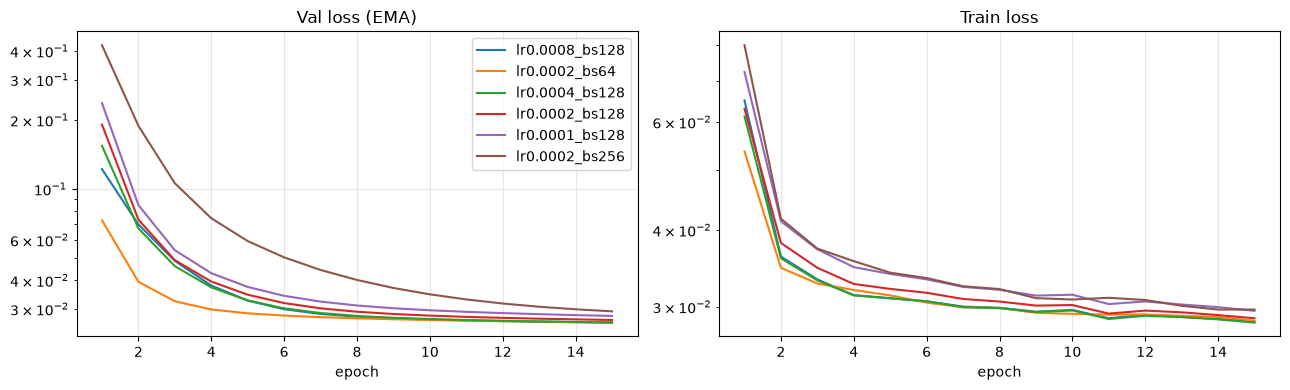

In [129]:
tune_root = os.path.join("checkpoints", "tuning")
tune_rows = []
if os.path.isdir(tune_root):
    for d in sorted(os.listdir(tune_root)):
        p = os.path.join(tune_root, d, "done.json")
        if os.path.exists(p):
            with open(p) as f:
                tune_rows.append(json.load(f))

if not tune_rows:
    print("Belum ada hasil tuning (set TUNING['RUN_TUNING']=True lalu jalankan sel sebelumnya).")
else:
    os.makedirs(os.path.join("reports", "tuning"), exist_ok=True)
    tune_res = pd.DataFrame(tune_rows).sort_values("best_val").reset_index(drop=True)
    tune_res["selisih_train_val"] = tune_res["final_train"] - tune_res["best_val"]
    tune_res.to_csv(os.path.join("reports", "tuning", "results.csv"), index=False)
    display(tune_res[["run", "lr", "batch_size", "best_val", "best_epoch", "final_train", "minutes"]])

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for _, r in tune_res.iterrows():
        d = pd.read_csv(os.path.join(tune_root, r["run"], "training_log.csv"))
        ax[0].plot(d["epoch"], d["val_loss"], label=r["run"])
        ax[1].plot(d["epoch"], d["train_loss"], label=r["run"])
    ax[0].set_title("Val loss (EMA)")
    ax[1].set_title("Train loss")
    for a in ax:
        a.set_xlabel("epoch")
        a.set_yscale("log")
        a.grid(alpha=0.3)
    ax[0].legend()
    plt.tight_layout()
    plt.savefig(os.path.join("reports", "tuning", "val_curves.png"), dpi=150)
    plt.show()

In [130]:
if tune_rows:
    best = tune_res.iloc[0]
    base = tune_res[(tune_res["lr"] == 2e-4) & (tune_res["batch_size"] == 128)]
    print(f"Konfigurasi terbaik: {best['run']} (lr={best['lr']:g}, batch={int(best['batch_size'])}) "
          f"dengan val loss {best['best_val']:.5f} pada epoch {int(best['best_epoch'])}.")
    if len(base):
        b = base.iloc[0]
        delta = (b["best_val"] - best["best_val"]) / b["best_val"] * 100
        print(f"Baseline (lr=2e-4, batch=128): val loss {b['best_val']:.5f} -> selisih terhadap terbaik {delta:.2f}%.")
    print("Urutan (terbaik -> terburuk):", ", ".join(tune_res["run"]))

Konfigurasi terbaik: lr0.0008_bs128 (lr=0.0008, batch=128) dengan val loss 0.02612 pada epoch 15.
Baseline (lr=2e-4, batch=128): val loss 0.02682 -> selisih terhadap terbaik 2.63%.
Urutan (terbaik -> terburuk): lr0.0008_bs128, lr0.0002_bs64, lr0.0004_bs128, lr0.0002_bs128, lr0.0001_bs128, lr0.0002_bs256


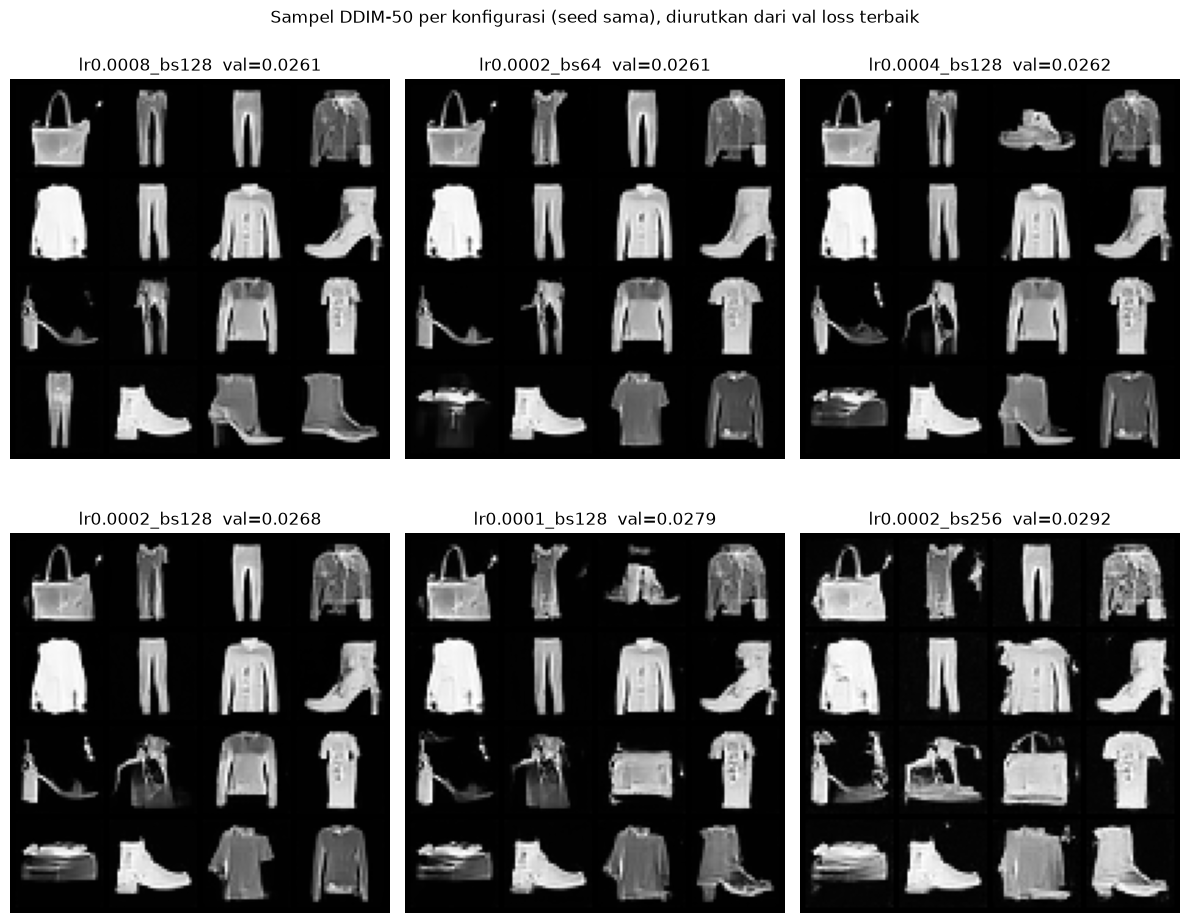

In [131]:
if tune_rows:
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    fig, axs = plt.subplots(2, 3, figsize=(12, 9.5))
    axs = axs.ravel()
    for a in axs:
        a.axis("off")
    for a, (_, r) in zip(axs, tune_res.iterrows()):
        m = UNet().to(dev)
        m.load_state_dict(torch.load(os.path.join(tune_root, r["run"], "best_model.pth"), map_location=dev))
        torch.manual_seed(0)
        diff = GaussianDiffusion(schedule=TUNING["SCHEDULE"]).to(dev)
        s = diff.sample_ddim(m, n=16, image_size=32, ddim_timesteps=50, device=dev)
        g = vutils.make_grid(s, nrow=4, normalize=True, value_range=(-1, 1))
        a.imshow(g.permute(1, 2, 0).cpu().numpy())
        a.set_title(f"{r['run']}  val={r['best_val']:.4f}")
    fig.suptitle("Sampel DDIM-50 per konfigurasi (seed sama), diurutkan dari val loss terbaik")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.subplots_adjust(hspace=0.12)
    plt.savefig(os.path.join("reports", "tuning", "samples.png"), dpi=150)
    plt.show()

### Kesimpulan tuning

Semua run memakai schedule linear, time embedding aktif, 15 epoch, dan val set yang sama. Nilai di bawah adalah val loss terbaik (bobot EMA); semuanya tercapai di epoch 15.

| Run | Val loss | Selisih dari baseline | Waktu |
|---|---|---|---|
| lr 8e-4, batch 128 | 0.02612 | -2.6% | 13.3 mnt |
| lr 2e-4, batch 64 | 0.02613 | -2.6% | 16.1 mnt |
| lr 4e-4, batch 128 | 0.02617 | -2.4% | 13.4 mnt |
| lr 2e-4, batch 128 (baseline) | 0.02682 | 0 | 13.5 mnt |
| lr 1e-4, batch 128 | 0.02794 | +4.2% | 13.4 mnt |
| lr 2e-4, batch 256 | 0.02925 | +9.1% | 12.2 mnt |

Yang bisa dibaca dari tabel dan kurva:

- Learning rate 1e-4 terlalu pelan untuk 15 epoch. Dari 2e-4 ke 4e-4 val loss turun, dan dari 4e-4 ke 8e-4 hampir tidak berubah, jadi kelihatannya sudah mendekati titik jenuh. Tidak ada tanda diverge sampai 8e-4.
- Batch 64 lebih baik daripada 128, dan batch 256 paling jelek. Dugaan kami penyebabnya jumlah langkah update: dengan 15 epoch, batch 64 melakukan sekitar 12.900 langkah, batch 128 sekitar 6.450, dan batch 256 sekitar 3.200. Dugaan ini belum kami uji terpisah (misalnya dengan jumlah langkah yang disamakan).
- Tiga run teratas hanya berbeda sekitar 0.2%, jauh lebih kecil dari yang mungkin muncul karena seed lain. Jadi kami tidak menyimpulkan ada satu pemenang. Yang cukup aman dikatakan: lr 4e-4 sampai 8e-4 atau batch 64 lebih baik daripada baseline, sedangkan lr 1e-4 dan batch 256 lebih buruk.
- Dari sampel, run dengan lr 1e-4 dan batch 256 punya lebih banyak bentuk yang rusak dan bercak di sekitar objek. Tiga run teratas lebih rapi, tapi bedanya tipis dan objek yang muncul hampir sama karena seed sampling sama.

Pilihan untuk dipakai selanjutnya: **lr 4e-4, batch 128**. Val loss-nya hampir sama dengan dua teratas, lebih hati-hati daripada 8e-4, dan lebih cepat daripada batch 64 (13,4 menit dibanding 16,1 menit).

Keterbatasan: tiap konfigurasi hanya dilatih sekali (satu seed), hanya 15 epoch dan kurvanya masih turun saat berhenti, dan tuning hanya dilakukan pada schedule linear. Loss yang lebih rendah juga belum tentu berarti gambar lebih bagus, jadi sampel tetap perlu dilihat.

# 6. Evaluasi & perbandingan
Sampel DDIM 50 langkah, proses denoising x_T → x_0, dan kurva loss.

In [132]:
def load_run(run_name, device="cuda"):
    """Bangun model + diffusion dari checkpoints/<run_name>/ (config.json + best_model.pth)."""
    run_dir = os.path.join("checkpoints", run_name)
    with open(os.path.join(run_dir, "config.json")) as f:
        cfg = json.load(f)
    model = UNet(use_time_emb=cfg["use_time_emb"]).to(device)
    model.load_state_dict(torch.load(os.path.join(run_dir, "best_model.pth"), map_location=device))
    diffusion = GaussianDiffusion(num_timesteps=cfg["timesteps"], schedule=cfg["schedule"]).to(device)
    return model, diffusion, cfg

In [133]:
def _to_01(x):
    return ((x + 1.0) / 2.0).clamp(0, 1)

In [134]:
def save_sample_grid(model, diffusion, path, title, device, n=64, seed=0):
    torch.manual_seed(seed)
    samples = diffusion.sample_ddim(model, n=n, channels=1, image_size=32, device=device)
    grid = vutils.make_grid(_to_01(samples), nrow=8)
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0).cpu().numpy(), cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.close()

In [135]:
def save_denoising(model, diffusion, path, title, device, n_rows=6, n_cols=10, seed=0):
    """Baris = sampel berbeda, kolom = langkah DDIM dari x_T (noise) ke x_0."""
    torch.manual_seed(seed)
    _, traj = diffusion.sample_ddim(model, n=n_rows, channels=1, image_size=32,
                                    device=device, return_intermediates=True)
    idx = torch.linspace(0, len(traj) - 1, n_cols).round().long().tolist()
    frames = torch.stack([_to_01(traj[i]) for i in idx], dim=1)  # (n_rows, n_cols, 1, H, W)
    grid = vutils.make_grid(frames.flatten(0, 1), nrow=n_cols, padding=2, pad_value=1.0)
    plt.figure(figsize=(12, 1.4 * n_rows))
    plt.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray")
    plt.title(title + "  (kiri: x_T noise -> kanan: x_0)")
    plt.axis("off")
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.close()

In [136]:
def plot_loss(run_names, path):
    """Kurva loss untuk satu atau beberapa run (garis putus = train, tebal = val)."""
    plt.figure(figsize=(7, 4.5))
    for i, name in enumerate(run_names):
        df = pd.read_csv(os.path.join("checkpoints", name, "training_log.csv"))
        color = f"C{i}"
        # log lama (sebelum ada validasi) hanya punya kolom 'loss'
        train_col = "train_loss" if "train_loss" in df else "loss"
        plt.plot(df["epoch"], df[train_col], "--", color=color, alpha=0.6, label=f"{name} train")
        if "val_loss" in df and df["val_loss"].notna().any():
            plt.plot(df["epoch"], df["val_loss"], "-", color=color, label=f"{name} val")
    plt.xlabel("epoch")
    plt.ylabel("MSE loss (noise)")
    plt.yscale("log")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.close()

In [137]:
def evaluate_run(run_name, device="cuda"):
    """Hasilkan grid sampel, visualisasi denoising, dan kurva loss ke reports/<run_name>/."""
    out_dir = os.path.join("reports", run_name)
    os.makedirs(out_dir, exist_ok=True)
    model, diffusion, cfg = load_run(run_name, device)
    tag = f"{run_name} ({cfg['schedule']}, time_emb={cfg['use_time_emb']})"

    save_sample_grid(model, diffusion, os.path.join(out_dir, "generated_grid.png"),
                     f"DDIM 50 langkah - {tag}", device)
    save_denoising(model, diffusion, os.path.join(out_dir, "denoising.png"), tag, device)
    plot_loss([run_name], os.path.join(out_dir, "loss_curve.png"))
    print(f"Evaluasi {run_name} disimpan di {out_dir}/")

In [138]:
# semua run yang punya checkpoint (termasuk yang baru dilatih di bagian 4)
RUNS = sorted(d for d in os.listdir("checkpoints") if os.path.exists(f"checkpoints/{d}/best_model.pth"))
print("Run terdeteksi:", RUNS)
device = "cuda" if torch.cuda.is_available() else "cpu"
rows = []
for r in RUNS:
    df = pd.read_csv(f"checkpoints/{r}/training_log.csv")
    tcol = "train_loss" if "train_loss" in df else "loss"
    rows.append({"run": r, "epoch": len(df), "train_loss": round(df[tcol].iloc[-1], 4),
                 "val_loss": round(df["val_loss"].iloc[-1], 4) if "val_loss" in df else None})
pd.DataFrame(rows).set_index("run")

Run terdeteksi: ['cosine', 'linear', 'linear_notime']


,epoch,train_loss,val_loss
run,,,
cosine,50,0.0485,0.0459
linear,50,0.0267,NaN
linear_notime,50,0.0278,0.0259


Catatan: loss antar schedule tidak sebanding. `linear` dilatih sebelum validasi ditambahkan, sehingga tidak punya `val_loss`.

### Kurva loss

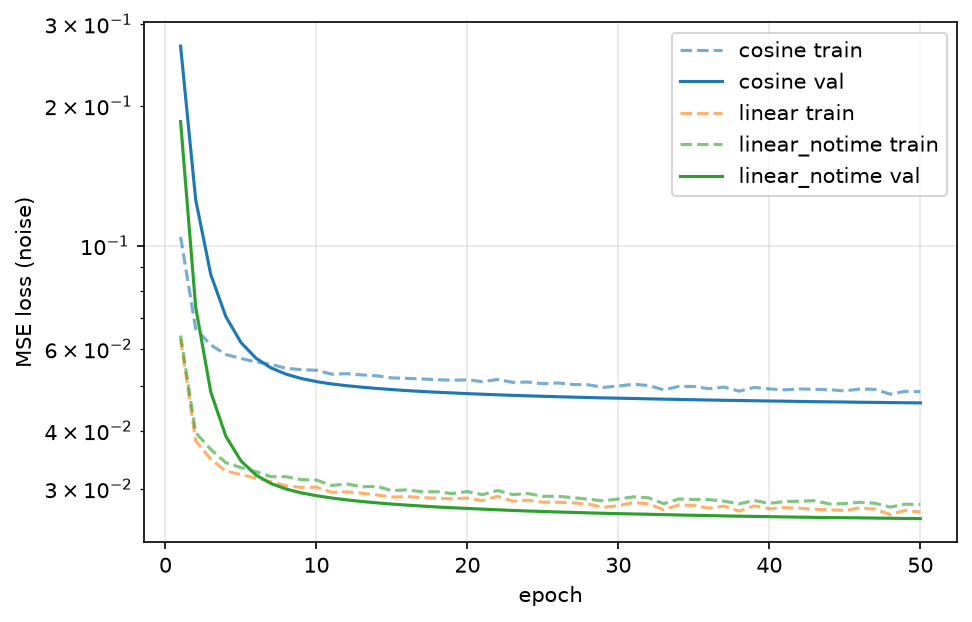

In [139]:
plot_loss(RUNS, "reports/compare_loss.png")
display(Image("reports/compare_loss.png"))

### Sampel DDIM per run

`RERUN = True` membuat ulang gambar di `reports/<run>/`; default memakai gambar yang sudah tersimpan.

### cosine

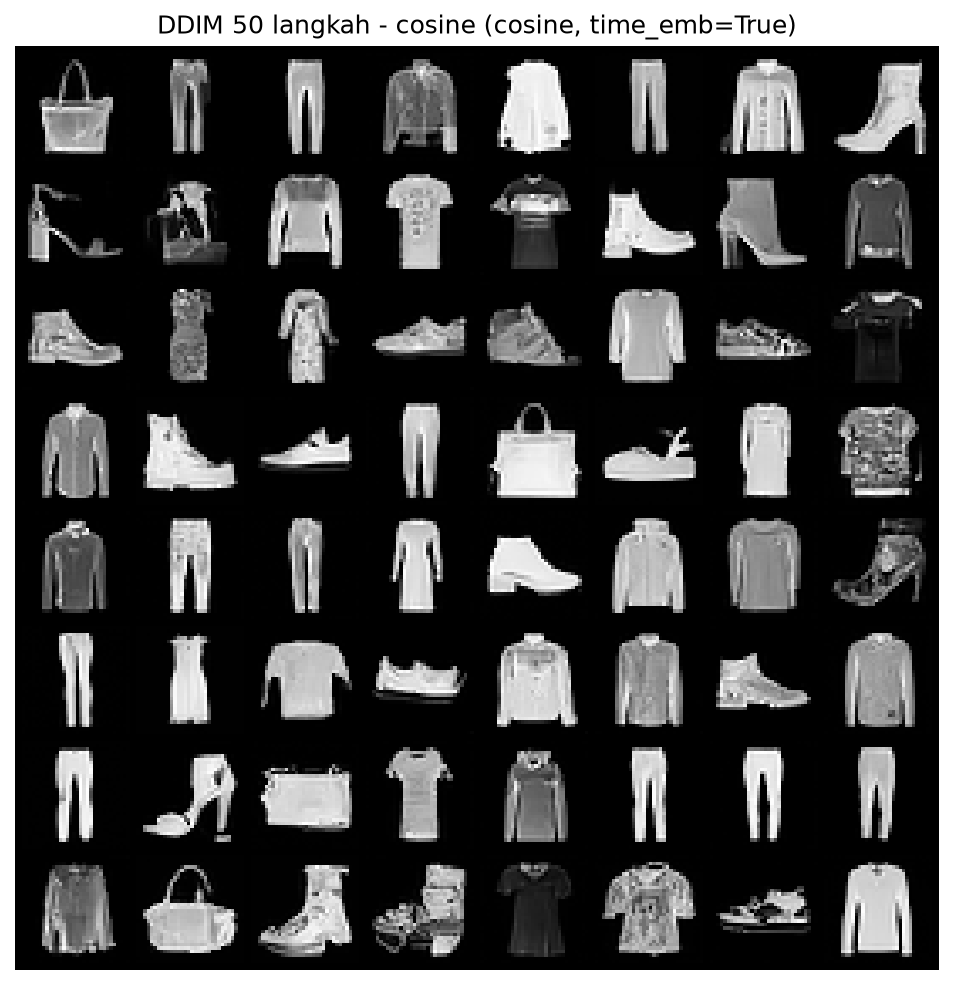

### linear

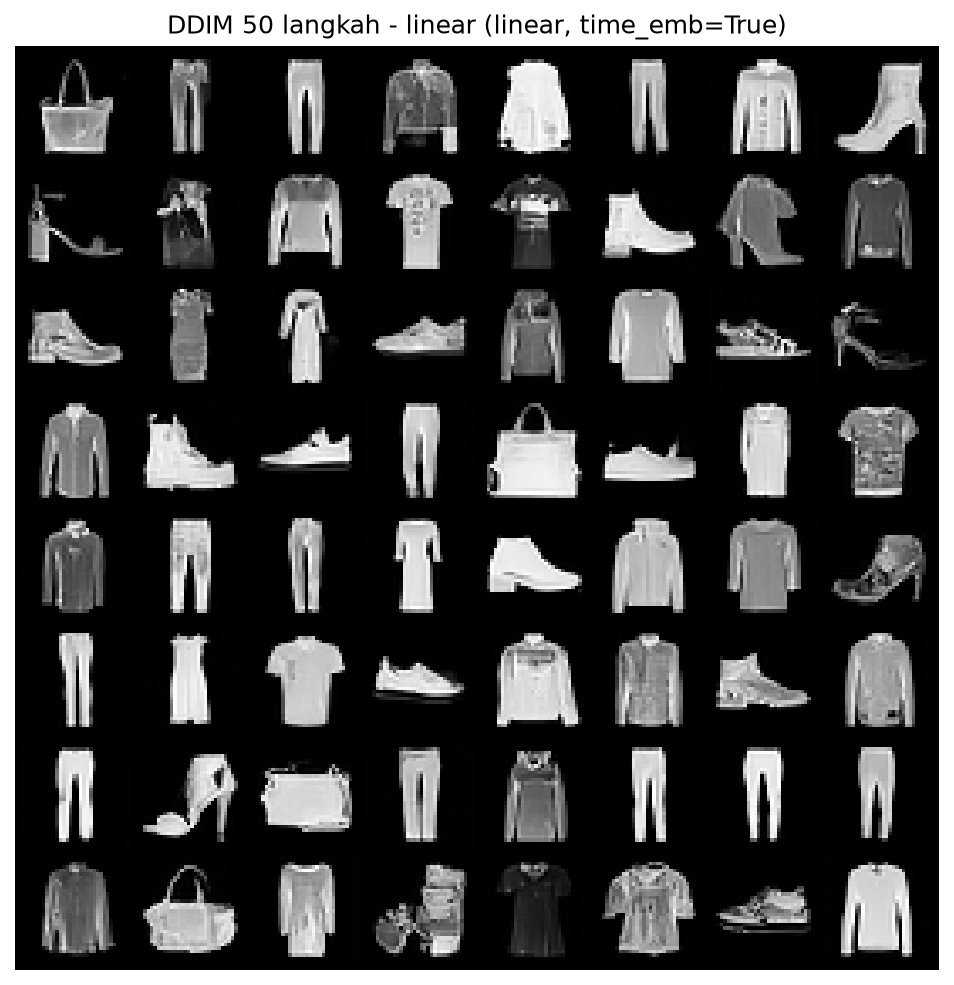

### linear_notime

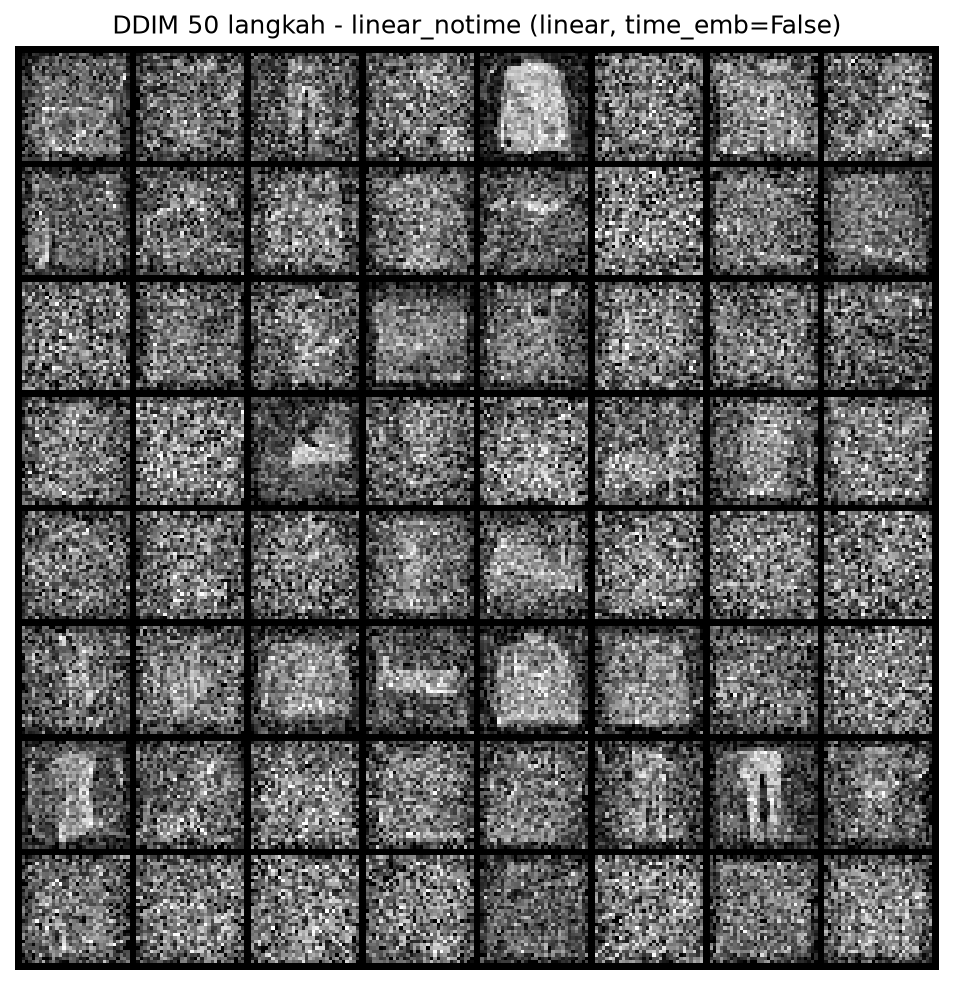

In [140]:
RERUN = False   # True = hasilkan ulang semua gambar (butuh checkpoint & GPU/CPU)
for r in RUNS:
    # gambar dibuat otomatis kalau belum ada (mis. run yang baru dilatih)
    if RERUN or not os.path.exists(f"reports/{r}/generated_grid.png"):
        evaluate_run(r, device=device)
    display(Markdown(f"### {r}"))
    display(Image(f"reports/{r}/generated_grid.png", width=520))

### Proses denoising x_T → x_0

### cosine

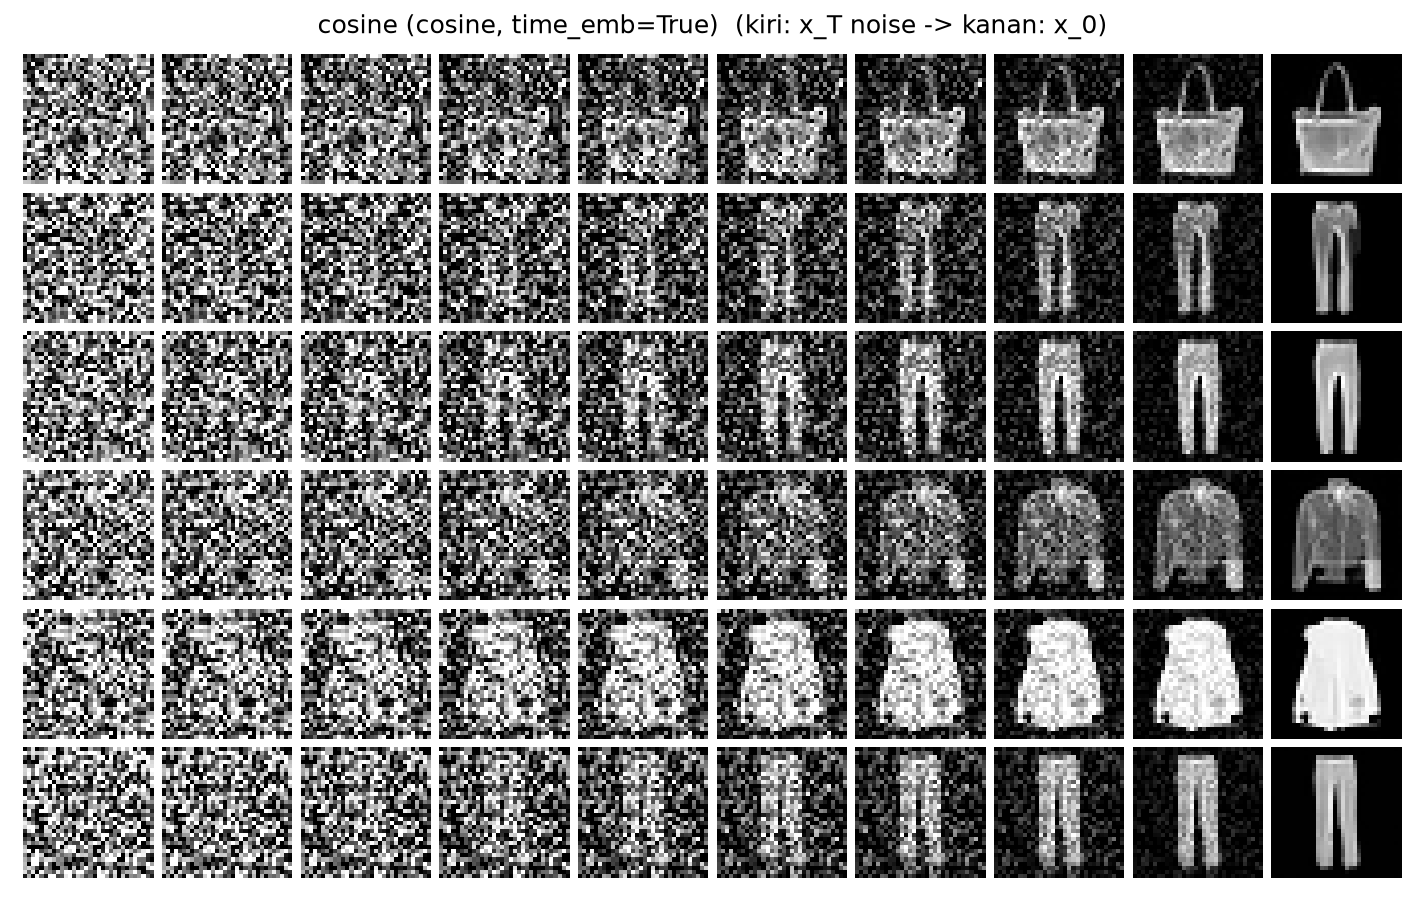

### linear

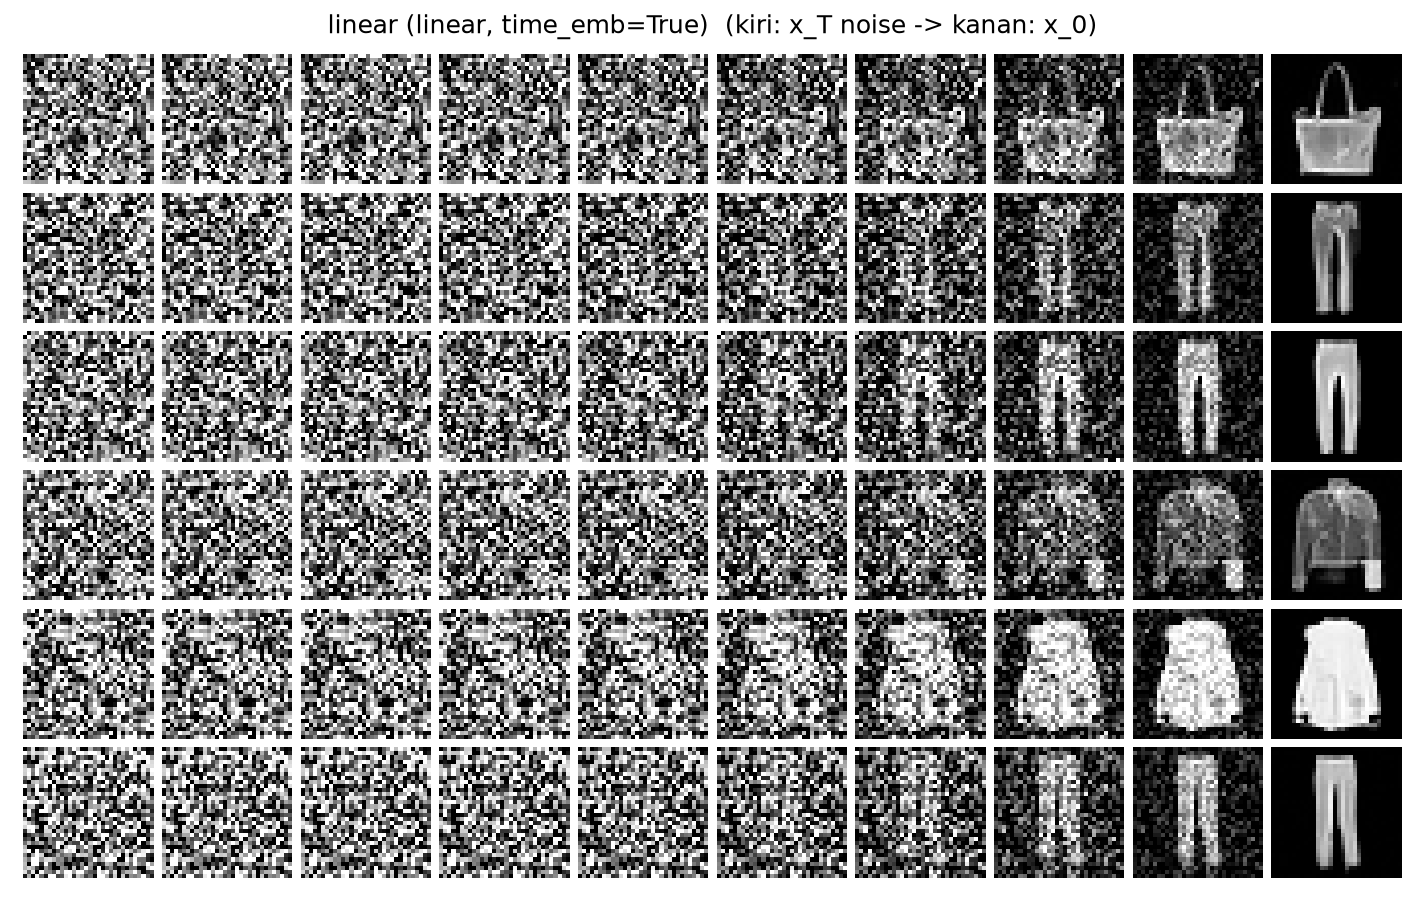

### linear_notime

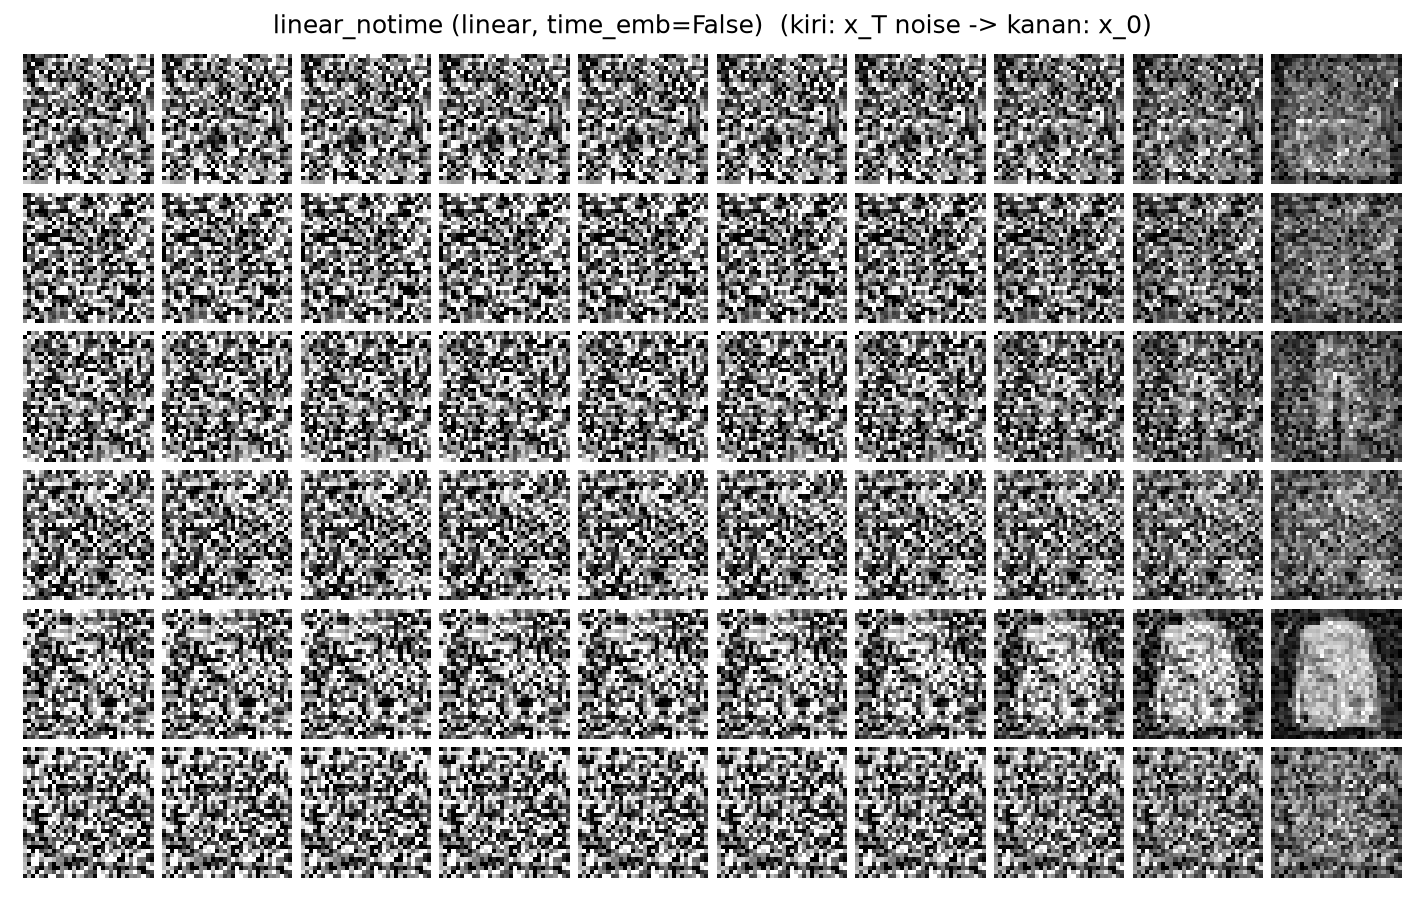

In [141]:
for r in RUNS:
    display(Markdown(f"### {r}"))
    display(Image(f"reports/{r}/denoising.png", width=820))

### Kesimpulan eksperimen
- **Timestep embedding krusial.** `linear_notime` memiliki loss hampir sama dengan `linear`, tetapi sampelnya hampir seluruhnya noise.
  Tanpa `t`, model tidak tahu langkah yang sedang dikerjakan saat sampling bertahap, meski loss rata-rata terlihat bagus.
- **Linear vs cosine:** sampel keduanya sama-sama jelas (tas, celana, sepatu, gaun, kemeja). Dari pengamatan visual belum dapat disimpulkan mana yang lebih baik;
  perlu metrik kuantitatif (mis. FID/KID) untuk itu.
- Loss tidak cukup sebagai satu-satunya indikator kualitas generatif.

# 7. Tes
Isi `tests/test_*.py` dijalankan langsung (tanpa pytest), ditambah tes U-Net.

In [142]:
def test_dataset_split_lengths():
    config = load_data_config()
    train_ds, val_ds, test_ds = build_datasets(config)
    
    assert len(train_ds) == 55000, "Train dataset harus berukuran 55000"
    assert len(val_ds) == 5000, "Val dataset harus berukuran 5000"
    assert len(test_ds) == 10000, "Test dataset harus berukuran 10000"

In [143]:
def test_stratified_split():
    config = load_data_config()
    _, val_ds, _ = build_datasets(config)
    
    # Tiap kelas harus berjumlah 500 di validation
    class_counts = torch.bincount(val_ds.targets)
    assert (class_counts == 500).all(), "Split stratified gagal, distribusi tidak merata"

In [144]:
def test_tensor_contract_and_range():
    config = load_data_config()
    loaders = build_dataloaders(config)
    batch = next(iter(loaders.train))
    
    # Shape: [Batch, 1, 32, 32]
    assert batch.shape[1:] == (1, 32, 32), f"Bentuk tensor salah: {batch.shape}"
    
    # Rentang [-1, 1]
    assert batch.min() >= -1.0, "Nilai minimum di bawah -1.0"
    assert batch.max() <= 1.0, "Nilai maksimum di atas 1.0"
    
    # Padding harus -1 (pojok gambar)
    assert batch[0, 0, 0, 0].item() == -1.0, "Padding hitam gagal menjadi -1.0"

In [145]:
def test_alpha_bar_monotonicity():
    diff = GaussianDiffusion(num_timesteps=1000, schedule="linear")
    alphas_bar = diff.alphas_cumprod
    # Harus selalu turun
    assert torch.all(alphas_bar[:-1] > alphas_bar[1:])

In [146]:
def test_q_sample_t0():
    diff = GaussianDiffusion(num_timesteps=1000)
    x0 = torch.ones((1, 1, 32, 32)) # Dummy data
    t0 = torch.zeros((1,), dtype=torch.long)
    # Di step 0, x_t harus hampir sama dengan x0 (karena noise belum maksimal)
    x_t = diff.q_sample(x0, t0, noise=torch.zeros_like(x0)) 
    assert torch.allclose(x0, x_t, atol=1e-2)

In [147]:
def test_ddim_deterministic_seed():
    # Setup dummy model
    class DummyModel(torch.nn.Module):
        def forward(self, x, t): return torch.zeros_like(x)
        
    model = DummyModel()
    diff = GaussianDiffusion(num_timesteps=100)
    
    torch.manual_seed(42)
    sample1 = diff.sample_ddim(model, n=1, image_size=32, ddim_timesteps=10, eta=0.0, device="cpu")
    
    torch.manual_seed(42)
    sample2 = diff.sample_ddim(model, n=1, image_size=32, ddim_timesteps=10, eta=0.0, device="cpu")
    
    assert torch.allclose(sample1, sample2)

In [148]:
def test_unet_shapes_and_time_dependence():
    x = torch.randn(2, 1, 32, 32)
    m = UNet()
    assert m(x, torch.tensor([0, 999])).shape == x.shape
    assert not torch.allclose(m(x, torch.tensor([0, 0])), m(x, torch.tensor([500, 500]))), "output harus bergantung pada t"

def test_unet_ablation_ignores_t():
    x = torch.randn(2, 1, 32, 32)
    m = UNet(use_time_emb=False)
    assert torch.allclose(m(x, torch.tensor([0, 0])), m(x, torch.tensor([500, 500]))), "tanpa time emb, output tak boleh bergantung pada t"

In [149]:
tests = {n: f for n, f in list(globals().items()) if n.startswith("test_") and callable(f)}
failed = 0
for name, fn in tests.items():
    try:
        fn(); print("LULUS ", name)
    except Exception as e:
        failed += 1; print("GAGAL ", name, "->", repr(e))
print(f"\n{len(tests) - failed}/{len(tests)} tes lulus")
assert failed == 0

LULUS  test_dataset_split_lengths
LULUS  test_stratified_split
LULUS  test_tensor_contract_and_range
LULUS  test_alpha_bar_monotonicity
LULUS  test_q_sample_t0
LULUS  test_ddim_deterministic_seed
LULUS  test_unet_shapes_and_time_dependence
LULUS  test_unet_ablation_ignores_t

8/8 tes lulus
